# <center> ISEL - CSM </center>
## <center>Semestre 2023/24 </center>
###  <center> Trabalho 1 - Codificação de Sinais Multimédia</center>

Trabalho realizado por:
* João Ramos, numero <b> 50730 </b>
* Miguel Alcobia, numero <b> 50746 </b>
* Fábio Pestana, numero <b> 50756 </b>

<b> Turma 42D </b> <br></br>
<b> Docente: Gonçalo Valadão </b>

### 1.
Abra o ficheiro com a imagem "lena.tif" e apresente a imagem.<br>
Verifique para que servem os métodos "dtype"e "shape":

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# %matplotlib widget

x_img = cv.imread("lena.tif")
cv.imshow('Original Image', x_img)

print("dtype: ", x_img.dtype)
print("shape: ", x_img.shape)

cv.waitKey(0)
cv.destroyAllWindows()

dtype:  uint8
shape:  (512, 512, 3)


> Comentários:

``dtype`` serve para ver o tipo de dados associado à imagem. Neste caso é ``uint8``, o que signifca que cada pixel corresponde a 1 byte (8 bits) e tem como valor mínimo 0 e máximo 255.

``shape`` mostra um tuple com o número de linhas, colunas e canais (neste caso o 3 corresponde a RGB, ou a BGR como é o caso da bibliteca OpenCV).


### 2.
Grave a mesma imagem, mas agora em formato "JPEG" com diferentes qualidades.<br>
Verifique visualmente a qualidade das imagens assim como o tamanho do ficheiro.<br>
Produza o código para calcular a taxa de compressão, a SNR e a PSNR.

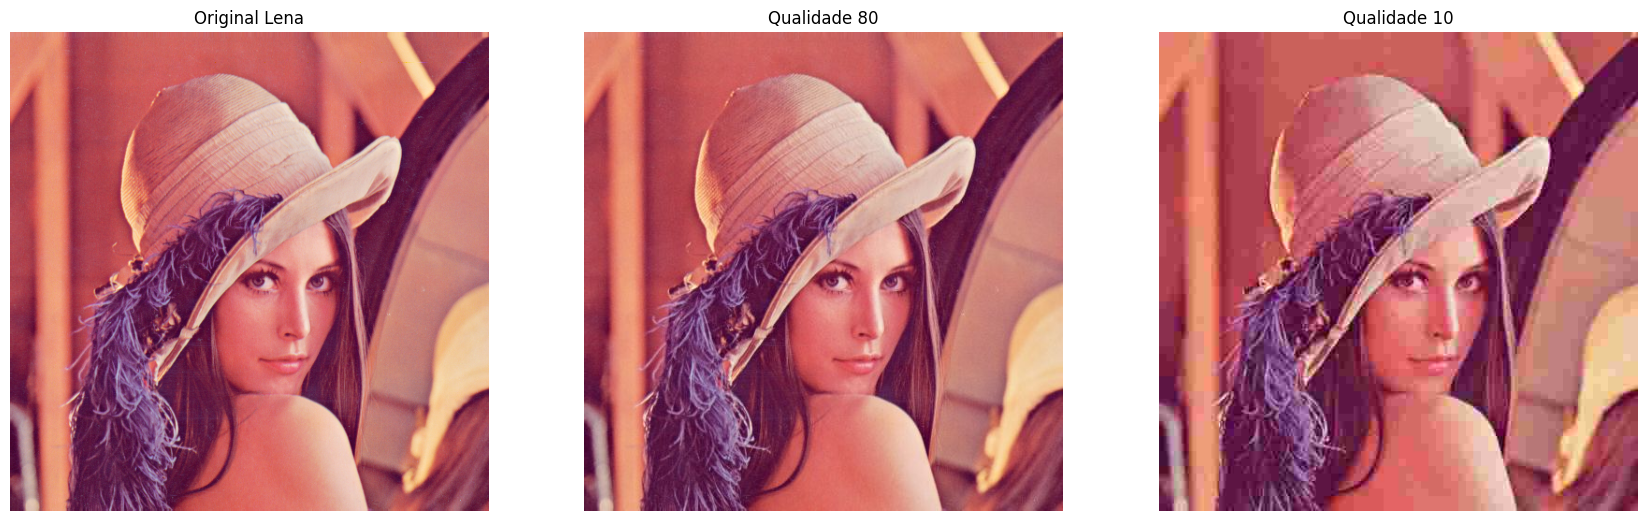

In [2]:
import os

Org_path =  'lena.tif'
Qual10_path = 'lena_qual10.jpg'
Qual80_path = 'lena_qual80.jpg'

# (cv.IMWRITE_JPEG_QUALITY, x) -> coloca a qualidade da imagem a x%
cv.imwrite(Qual80_path, x_img, (cv.IMWRITE_JPEG_QUALITY, 80))
cv.imwrite(Qual10_path, x_img, (cv.IMWRITE_JPEG_QUALITY, 10))

Img_org = plt.imread(Org_path)
Img_qual80 = plt.imread(Qual80_path)
Img_qual10 = plt.imread(Qual10_path)

plt.figure(figsize=(21, 7))
           
plt.subplot(131)
plt.imshow(Img_org)
plt.axis('off')
plt.title('Original Lena')

plt.subplot(132)
plt.imshow(Img_qual80)
plt.axis('off')
plt.title('Qualidade 80')

plt.subplot(133)
plt.imshow(Img_qual10)
plt.axis('off')
plt.title('Qualidade 10')

plt.show()

> Comentário:    

&emsp; Como podemos observar, quanto menor for a percentagem pedida, pior será a qualidade da imagem, visto que terá mais ruído e ficará mais pixelizado. Isto não é muito notável entre a imagem original e a imagem de qualidade 80%, pois a qualidade da imagem comprimida ainda é capaz de enganar o olho humano. Ao contrário da imagem de 10% de qualidade, onde é bastante visível uma significativa perda de informação.

#### Tamanho de ficheiros

In [3]:
Img_size = os.path.getsize(Org_path)
Qual80_size = os.path.getsize(Qual80_path)
Qual10_size = os.path.getsize(Qual10_path)

print("Imagem original size: " , Img_size, "bytes")
print("Imagem qualidade 80 size: " , Qual80_size, "bytes")
print("Imagem qualidade 10 size: " , Qual10_size, "bytes")

Imagem original size:  786572 bytes
Imagem qualidade 80 size:  44124 bytes
Imagem qualidade 10 size:  9566 bytes


> Comentário:    

&emsp; Utilizando a função do módulo os.path ``os.path.getsize(filename)`` que retorna o tamanho em bytes de um ficheiro através do seu caminho, é possivel observar que o tamanho de ambas imagens (de 80% e 10% de qualidade) é significativamente menor que a imagem original.
<br></br>

#### Fórmulas do SNR e do PSNR.

$$
SNR(dBs) = 10 \log_{10} \left( \frac{\Sigma_l \Sigma_c I_{org}[l,c]^2}{\Sigma_l \Sigma_c (I_{org}[l,c]-I_{app}[l,c])^2} \right)
$$
$$
PSNR(dBs) = 10 \log_{10} \left( \frac{\Sigma_l \Sigma_c 255^2}{\Sigma_l \Sigma_c (I_{org}[l,c]-I_{app}[l,c])^2} \right)
$$


In [4]:
# Taxa de Compressao:
#   tamanho Imagem Original / tamanho Imagem alterada
def taxaCompressao(img_org_size, img_app_size):
    """Taxa de Compressão

    Calcula a taxa de compressão entre o tamanho da imagem original e a imagem alterada

    Args:
        img_org_size: Tamanho da imagem original
        img_app_size: Tamanho da imagem alterada
    Returns:
        1/factor_qualidade: Taxa de compressão
    """
    factor_qualidade = img_org_size/img_app_size
    return 1/factor_qualidade


# Função SNR
def snr(img_org, img_app):
    """SNR - Signal-to-Noise Ratio

    Args:
        img_org: Imagem original
        img_app: Imagem com ruído

    Returns:
        snr_value: Valor do SNR
    """
    # Conversão dos valores da imagem para float
    img_org = img_org * 1.0
    img_app = img_app * 1.0

    # Calcular o sinal da imagem original
    signal = np.mean(img_org ** 2)

    # Calcular o ruído como a diferença entre as duas imagens (Mean-Square Error)
    noise = np.mean((img_org - img_app) ** 2)

    # Calcular a SNR (dB)
    snr_value = 10 * np.log10(signal / noise)
    return snr_value


# Função PSNR
def psnr(img_org, img_app):
    """PSNR - Peak Signal-to-Noise Ratio

    Args:
        img_org: Imagem original
        img_app: Imagem com ruído

    Returns:
        psnr_value: Valor do PSNR
    """
    # Conversão dos valores da imagem para float
    img_org = img_org * 1.0
    img_app = img_app * 1.0

    # Calcular o sinal da imagem original
    signal = np.mean(255 ** 2)

    # Calcular o ruído como a diferença entre as duas imagens (Mean-Square Error)
    noise = np.mean((img_org - img_app) ** 2)

    # Calcular a SNR (dB)
    psnr_value = 10 * np.log10(signal / noise)
    return psnr_value

#### Testes

In [5]:
# Leitura das imagens com ruído
img_noise_80 = cv.imread(Qual80_path)
img_noise_10 = cv.imread(Qual10_path)

print("Testes com a imagem de qualidade 80")
snr_80 = snr(x_img, img_noise_80)
psnr_80 = psnr(x_img, img_noise_80)
taxaCompressao_80 = taxaCompressao(Img_size, Qual80_size)

print("SNR com a imagem de qualidade 80: ", snr_80,"dB\nPSNR com a imagem de qualidade 80: ", psnr_80,"dB",
       "\nTaxa de Compressao com a imagem de qualidade 80: ", taxaCompressao_80)

print("\nTestes com a imagem de qualidade 10")
snr_10 = snr(x_img, img_noise_10)
psnr_10 = psnr(x_img, img_noise_10)
taxaCompressao_10 = taxaCompressao(Img_size, Qual10_size)

print("SNR com a imagem de qualidade 10: ", snr_10,"dB\nPSNR com a imagem de qualidade 10: ", psnr_10,"dB",
       "\nTaxa de Compressao com a imagem de qualidade 10: ", taxaCompressao_10)

Testes com a imagem de qualidade 80
SNR com a imagem de qualidade 80:  28.468534958720454 dB
PSNR com a imagem de qualidade 80:  33.606097256534746 dB 
Taxa de Compressao com a imagem de qualidade 80:  0.05609658111399846

Testes com a imagem de qualidade 10
SNR com a imagem de qualidade 10:  22.391956905436455 dB
PSNR com a imagem de qualidade 10:  27.529519203250743 dB 
Taxa de Compressao com a imagem de qualidade 10:  0.012161633010074094


### 3.
Converta a imagem que está na variável x_img para níveis de cinzento, usando o método "cvtColor" e grave o resultado.<br>
Este método aplica a transformação Y = R ∗ 299/1000 + G ∗ 587/1000 + B ∗ 114/1000, justifique a utilização desta equação.<br>
Verifique também o tamanho do ficheiro e compare-o com o ficheiro original.

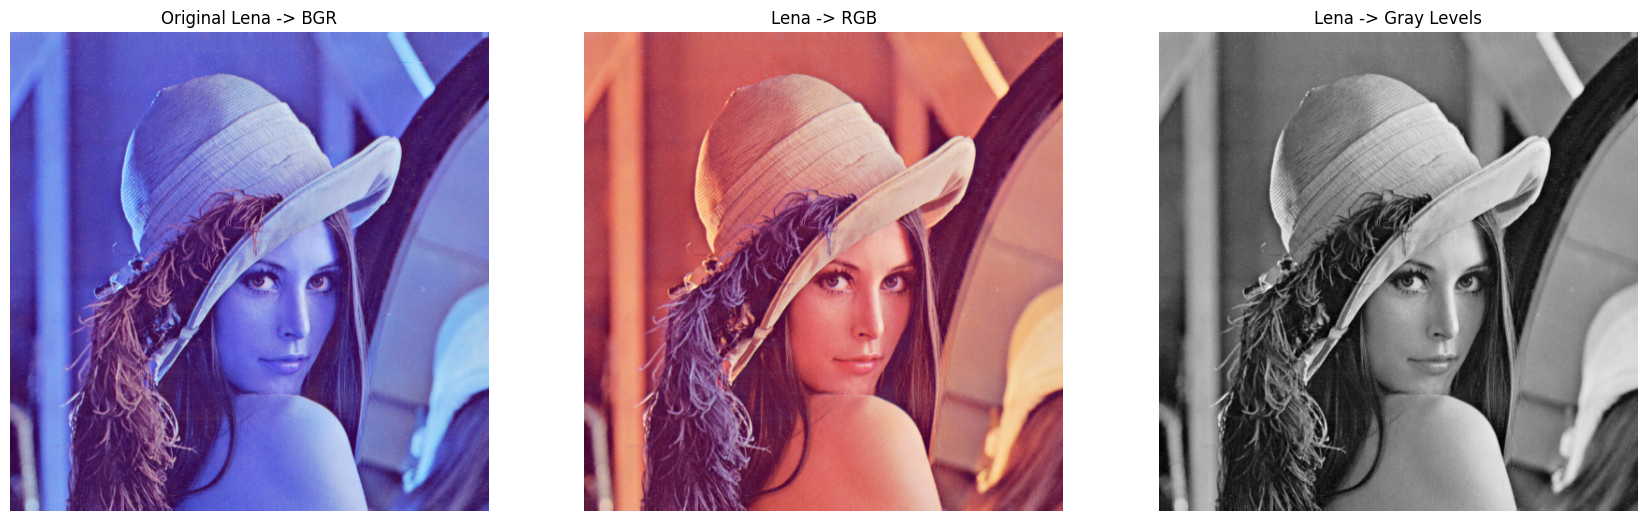

Imagem original size:  786572 bytes
Imagem com os niveis de cinzentos:  263222 bytes


In [6]:
Image_GrayLevels = 'lena_greyLevels.bmp'

x_img_g = cv.cvtColor(x_img, cv.COLOR_BGR2GRAY)
cv.imshow("Gray Image", x_img_g)

cv.waitKey(0)
cv.destroyAllWindows()

# Gravar a imagem em GreyLevels
cv.imwrite(Image_GrayLevels, x_img_g)

img_gray = plt.imread(Image_GrayLevels)

plt.figure(figsize=(21, 7))
           
plt.subplot(131)
plt.imshow(x_img)
plt.axis('off')
plt.title('Original Lena -> BGR')

plt.subplot(132)
plt.imshow(Img_org)
plt.axis('off')
plt.title('Lena -> RGB')

plt.subplot(133)
# cmap faz um mapeamento para tons de cinza "reais"
plt.imshow(img_gray, cmap='gray')
plt.axis('off')
plt.title('Lena -> Gray Levels')

plt.show()

GrayLevels_size = os.path.getsize(Image_GrayLevels)

print("Imagem original size: " , Img_size, "bytes")
print("Imagem com os niveis de cinzentos: " , GrayLevels_size, "bytes")

>Comentário:

<center>Y = R ∗ 299/1000 + G ∗ 587/1000 + B ∗ 114/1000</center>

Esta equação é utilizada, porque considera a maneira com que o olho humano captura cada cor. Os pesos atribuídos a cada canal são baseados em estudos de sensibilidade espectral e pretendem refletir a forma como os seres humanos compreendem a luminosidade das cores.

O fator de 299/1000 para o canal vermelho, por exemplo, é maior porque o olho humano é menos sensível ao vermelho do que ao verde. Da mesma forma, o canal verde tem um peso maior (587/1000) porque o olho humano é mais sensível ao verde. O canal azul tem o menor peso (114/1000) visto que o olho humano é menos sensível ao azul.

### 4.
Apresente o histograma da imagem (em tons de cinzento) que está na variável x_img_g.<br>
Verifique quantos níveis de cinzento tem a imagem.

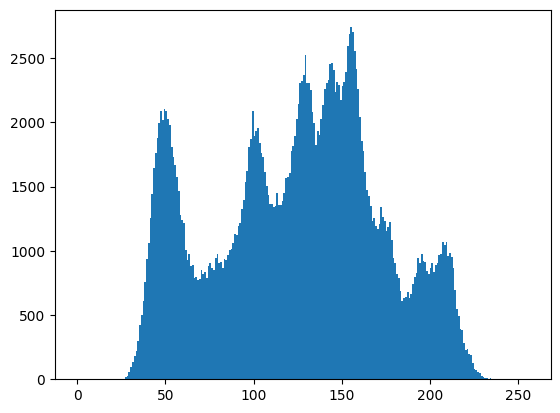

Número de níveis de cinza:  215
Valor mais repetido:  155


In [7]:
allImgValues = x_img_g.ravel()

plt.figure()
plt.hist(allImgValues, 256, [0,256])
plt.show()

#Cada valor de cinza diferente é contado uma vez e colocado numa lista. Assim, o comprimento desta lista é o número de níveis de cinza
print("Número de níveis de cinza: ", len(np.unique(allImgValues)))
print("Valor mais repetido: ", np.bincount(allImgValues).argmax())

> Comentários:

``len(np.unique(allImgValues))`` devolve o número de níveis de cinza. O ``np.unique(allImgValues)`` devolve um array com todos os valores presentes na imagem, sem repetições. Por fim, o ``len()`` vai devolver o tamanho desse array.

``np.bincount(allImgValues).argmax())`` devolve o valor mais repetido. O ``bincount()`` devolve um array com o número de ocorrências de cada elemento do ``allImgValues`` e o ``argmax()`` vai devolver o valor máximo do ``allImgValues``.

### 5.
Nos próximos trabalhos será necessário realizar operações com os valores de cada pixel. Para este efeito pode-se transformar a imagem para um array. O código seguinte representa o pixel mais significante da imagem.<br>
Apresente oito imagens, cada uma com o valor de cada bit para todos os pixeis.


``x_img_g >> i`` é um deslocamento para a direita ``>>``, onde deslocamos todos os bits da imagem para a direita ``i`` posições. Isso é útil para isolar o bit com que queremos trabalhar. Por exemplo, se i for 0, nenhum deslocamento ocorrerá. Se ``i`` for 1, todos os bits serão deslocados uma posição para a direita, e assim por diante. No final, o bit que está no local ``i`` em cada pixel será movido para a posição menos significativa (LSB).

``& 1`` é um operador ``AND`` bit a bit, onde comparamos cada bit dos valores resultantes do deslocamento com 1. Isso tem o efeito de colocar a 0 todos os bits, menos o bit menos significativo (LSB), que é o bit com que queremos trabalhar. Porque 1 em binário é 00000001, ou seja, o resultado final será 0 ou 1, dependendo do valor do bit que estamos a analisar.

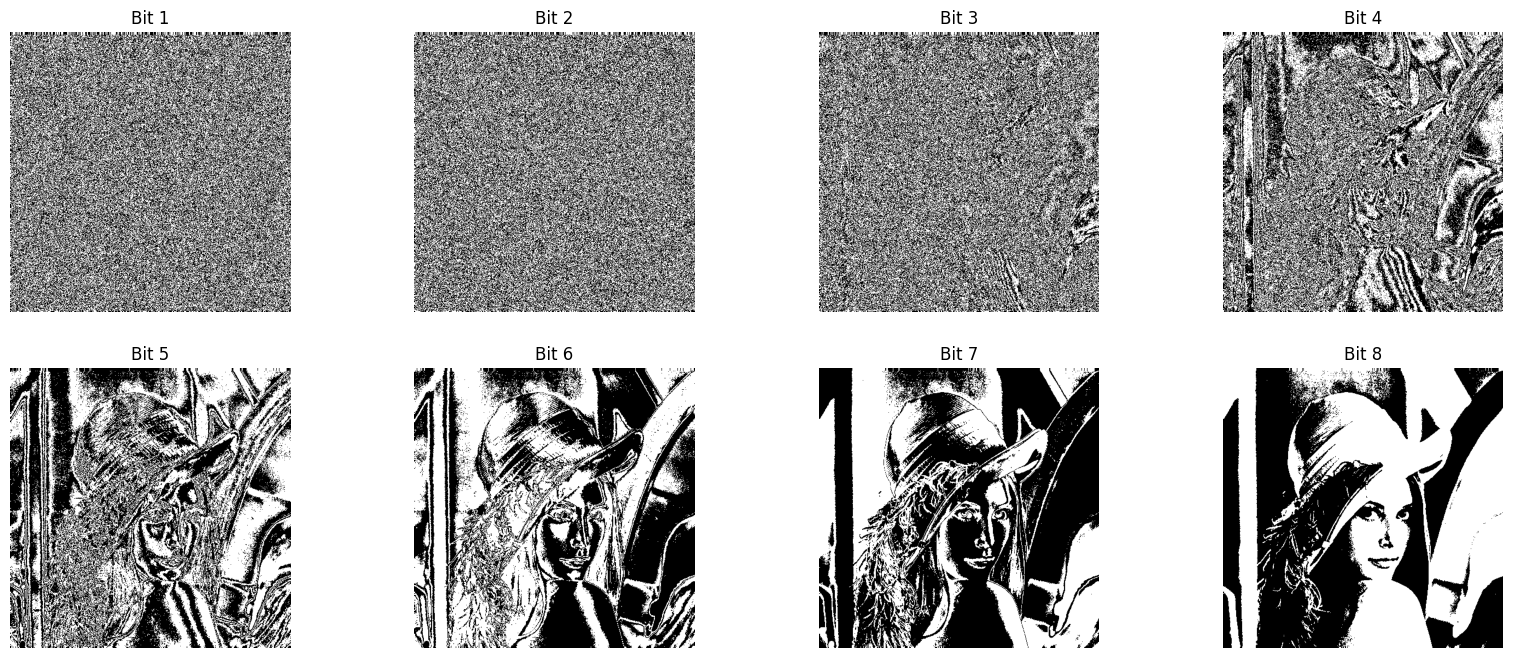

In [8]:
# Array para guardar as imagens para fazer display no plot
bit_planes=[]

# Loop para os 8 bits
for i in range(8):
    # Extrair o bit 'i' de cada pixel
    bit_i = (x_img_g >> i) & 1
    # Armazenar a imagem do bit
    bit_planes.append(bit_i)
    # Mostrar a imagem apenas com o bit 'i' ativado (em janelas)
    #cv.imshow(f'Bit {i}', bit_i * 255)
    #cv.waitKey(0)

#cv.destroyAllWindows()

# Mostrar a imagem apenas com o bit 'i' ativado (em plot)
plt.figure(figsize=(20, 8))
for i in range(len(bit_planes)):
    # Mostrar as imagens em um subplot 4x2
    plt.subplot(2, 4, (i+1))
    plt.imshow(bit_planes[i], cmap='gray')
    plt.axis('off')
    plt.title(f'Bit {i+1}')

plt.show()


### 6.
Construa uma função que realize o algoritmo de dithering Floyd Steinberg. Esta função recebe uma matrix (com os pixeis em tons de cinzento) e devolve uma matrix com valores a preto e branco.

Para aplicar o algoritmo de dithering percorremos cada pixel da imagem e verfica-se o seu valor é superior a 128 (metade de 256 [0, 255]) e se for, o seu valor passa a ser 255, se não é assumido 1 como valor.<br>
No final, distribuimos o erro de quantificação para os pixeis vizinhos consoante a matriz:

\begin{pmatrix}
\cdot & \cdot & \cdot \\
\cdot & \chi & \frac{7}{16} \\
\frac{3}{16} & \frac{5}{16} & \frac{1}{16}
\end{pmatrix}

In [9]:
def dither(img_gray):
    """Dithering Floyd Steinberg

    Aplica o algoritmo de dithering Floyd Steinberg. 
    Recebe uma matrix (com os pixeis em tons de cinzento) 
    e devolve uma matrix com valores a preto e branco.

    Args:
        img_gray : Imagem Orignal
    
    Returns:
        img_gray: Imagem com o filtro de Dithering
    """    
    img_gray = img_gray * 1.0
    img_height = img_gray.shape[0]
    img_width = img_gray.shape[1]

    for py in range(img_height):
        for px in range(img_width):
            old_pixel = img_gray[px][py]
            new_pixel = 255 if old_pixel > 128 else 0
            img_gray[px][py] = new_pixel
            erro = old_pixel - new_pixel
            
            # distribuição do erro de quantificação para os pixeis vizinhos consoante a matriz
            if (px + 1 < img_width):
                img_gray[px + 1][py] += int(erro * 7 / 16)
            if (px - 1 > 0 and py + 1 < img_height):
                img_gray[px - 1][py + 1] += int(erro * 3 / 16)
            if (py + 1 < img_height):
                img_gray[px][py+1] += int(erro * 5 / 16)
            if (px + 1 < img_width and py + 1 < img_height):
                img_gray[px + 1][py + 1] += int(erro * 1 / 16)

    return img_gray

#### Testes

(-0.5, 511.5, 511.5, -0.5)

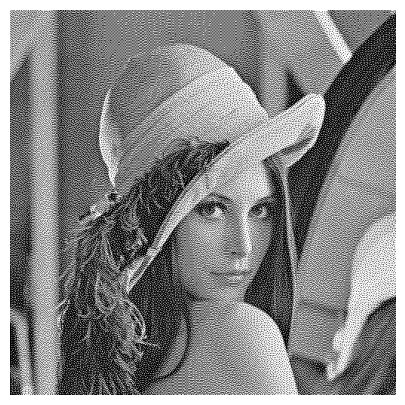

In [10]:
img_gray_dither = dither(x_img_g)
cv.imwrite('lena_dither.tif', img_gray_dither.astype(np.uint8))

plt.figure(figsize=(10,5))
plt.imshow(img_gray_dither, cmap='binary_r')
plt.axis("off")

### 7.
Construa uma função para gravar a matriz obtida na questão anterior (variável y) para um ficheiro binário.
Verifique o tamanho do ficheiro inicial e do ficheiro final. Calcule a taxa de compressão e meça o SNR e o PSNR.

In [11]:
def imgBWToBin(img, str_fileName):
    """Imagem preto e branco para ficheiro Binário

    Args:
        img: Imagem a converter
        str_fileName: nome a atribuir ao ficheiro .bin
    """
    img_height = img.shape[0]
    img_width = img.shape[1]

    img_bw_bit = np.zeros((img_width, img_height))

    for py in range(img_height):
        for px in range(img_width):
            img_bw_bit[px][py] = 1 if img[px][py] == 255 else 0
            #img_bw_bit[px][py] = 1 if img[px][py] > 127 else 0

    # Salva o arquivo .bin com o str_fileName
    with open(str_fileName, 'wb') as file:
        file.write(img_bw_bit)


# Função para teste para verificar se a conversão em binário foi bem feita
def binToImgBw(bin_file):
    """Binário para Imagem preto e branco

    Função para verificar se a conversão em binário foi bem feita

    Args:
        bin_file: ficheiro binário
    """
    # Lê o arquivo binário
    with open(bin_file, 'rb') as file:
        img_data = np.frombuffer(file.read(), dtype=np.float64)

    # Obtém a forma original da imagem
    img_width = int(np.sqrt(len(img_data)))
    img_height = img_width

    # Reconstrói a matriz 2D da imagem
    img = img_data.reshape((img_height, img_width))

    # Converte a imagem binária de volta para a escala de cinza
    img = (255 * img).astype(np.uint8)

    # Salva a imagem como TIFF usando OpenCV
    cv.imwrite("lena_bin2tif.tif", img)

    # Plota a imagem
    plt.imshow(img, cmap='gray')
    plt.title('Imagem TIFF (Reconstrução)')
    plt.axis('off')
    plt.show()


Na função ``imgBWToBin()`` percorremos a imagem com o algoritmo de dithering aplicado e verificamos o valor de cada pixel. Se o valor for 255 passa a 1, caso contrário o valor é igual a 0. Estes dados são guardados num array (``img_bw_bit``) e os valores deste array são gravados num ficheiro ``.bin``.
<br><br>
Na função ``binToImgBw`` elaboramos um código para reconstruir a imagem de dithering a partir do ficheiro binário. Como a imagem e quadrada, obtemos as dimensões dela fazendo a raiz quadrada do comprimento dos valores em binário e então usamos a função ``reshape()`` reconstruir a matriz 2D da imagem. Para voltarmos a ter os valores de dithering basta multiplicar por 255 (255 x 1 = 255 e 255 x 0 = 0).<br>
Com estes dados, já podemos guardar a imagem e verificar se o resultado é igual ao da imagem com o algoritmo de dithering aplicado.

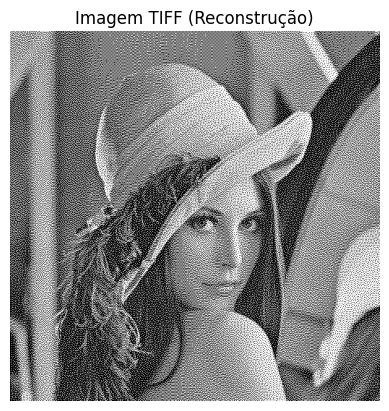

In [12]:
img_gray_dither_bin = imgBWToBin(img_gray_dither, "lena_bin_data.bin")
x_img_g_bin = imgBWToBin(x_img_g, "lena_g_bin_data.bin")

img_gray_dither_bin_size = os.path.getsize("lena_bin_data.bin")
x_img_g_bin_size = os.path.getsize("lena_g_bin_data.bin")
img_gray_dither_size = os.path.getsize("lena_dither.tif")


#Função de teste
binToImgBw("lena_bin_data.bin")

In [13]:
print("\nTestes entre a imagem a tons de cinza e a imagem com dithering")

snr_cd = snr(x_img_g, img_gray_dither)
psnr_cd = psnr(x_img_g, img_gray_dither)
taxaCompressao_cd = taxaCompressao(GrayLevels_size, img_gray_dither_size)
print("SNR: ", snr_cd," dB\nPSNR: ", psnr_cd," dB",
      "\nTaxa de Compressao: ", taxaCompressao_cd)

print("\nTestes entre a imagem a tons de cinza e a imagem com dithering em binário")

taxaCompressao_cd_bin = taxaCompressao(GrayLevels_size, img_gray_dither_bin_size)
print("\nTamanho do ficheiro da imagem GreyLevels: ", GrayLevels_size, 
      "\nTamanho do ficheiro .bin do Dithering: ", img_gray_dither_bin_size)
print("Taxa de Compressao: ", taxaCompressao_cd_bin)


Testes entre a imagem a tons de cinza e a imagem com dithering
SNR:  1.0661162167544247  dB
PSNR:  6.72253843167938  dB 
Taxa de Compressao:  0.18341931905387848

Testes entre a imagem a tons de cinza e a imagem com dithering em binário

Tamanho do ficheiro da imagem GreyLevels:  263222 
Tamanho do ficheiro .bin do Dithering:  2097152
Taxa de Compressao:  7.9672367811201195


### 8.
Crie uma função que apresente uma imagem com dimensão de 100 × 100 pixeis como se apresenta na figura. O ângulo de cada sector é dado por parâmetro passado à função (o ângulo é um valor inteiro entre 0 e 360 graus).

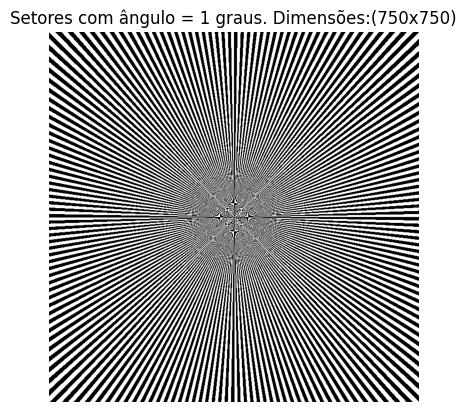

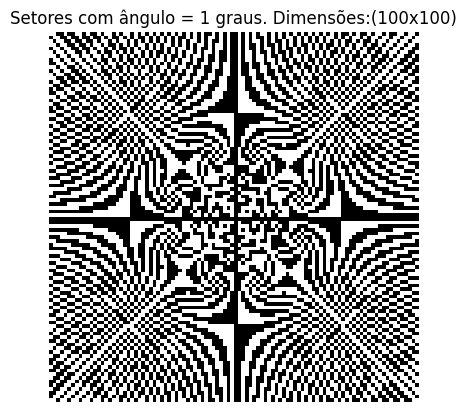

In [24]:
def plot_setores(angulo, altura = 750, largura = 750):
  """Dividir a imagem em setores

  Args:
      angulo: Ângulo de cada setor
      altura: Default a 750
      largura: Default a 750

  Raises:
      ValueError: Erro caso o ângulo esteja fora do intervalo de 0 a 360 graus
  """
  # Verifica se o ângulo está dentro do intervalo de 0 a 360 graus.
  if angulo < 0 or angulo > 360:
    raise ValueError("O ângulo deve estar entre 0 e 360 graus.")


  # Matriz tridimensional para representar a imagem
  # altura, largura, color channel
  img = np.zeros([altura, largura, 3], dtype=np.uint8)
  img.fill(255) #Todos os pixels da imagem são inicializados com 255 -> cor branca

  # Calculo do centro da imagem
  centro_y = altura / 2
  centro_x = largura / 2

  # Cores preto e branco
  cores_bw = [[0, 0, 0], [255, 255, 255]]

  for py in range(altura):
    for px in range(largura):
      # Angulo do pixel em relação ao centro da imagem
      angulo_pixel = np.degrees(np.arctan2((py - centro_y), (px - centro_x)))

      # Garante que o ângulo está dentro do intervalo de 0 a 360 graus
      # se não estiver colocamo-lo nele somando 360
      if angulo_pixel < 0:
        angulo_pixel += 360
      
      # Calculo do setor do pixel atual
      # setor = [0, num_setores-1]
      setor = int(angulo_pixel / angulo)
      
      # Define a cor do pixel com base no setor
      img[py, px] = cores_bw[setor % 2]

  
  plt.imshow(img)
  plt.title(f'Setores com ângulo = {angulo} graus. Dimensões:({largura}x{altura})')
  plt.axis('off')
  plt.show()


plot_setores(1)
plot_setores(1, 100, 100)


A função ``plot_setores(angulo)`` tem como objetivo dividir uma imagem em setores, para assim criar um efeito de ilusão de ótica. Inicialmente temos uma matriz tridimensional para representar a imagem onde
aplicamos ``.fill(255)`` para ter um canvas branco. Para cada pixel, vai se calcular o ângulo entre a linha que conecta o pixel ao centro da imagem e o eixo horizontal. Para depois determinarmos qual o setor que o pixel pertence e atribui-se a cor correspondente ao pixel (branco ou preto).
<br></br>

``np.degrees(np.arctan2((py - centro_y), (px - centro_x)))`` neste método destaca-se a seguinte linha de código, pois ela calcula o ângulo entre o vetor que liga o ponto ``(py, px)`` ao centro da imagem 
``(centro_y, centro_x)`` e o eixo horizontal. Para isto utiliza-se ``np.arctan2`` que retorna o ângulo em radianos, sendo que ``np.degrees`` o traduz para graus.
<br></br>

> Comentários:

&emsp; Para testes decidiu-se usar como parâmetros do método ``plot_setores(angulo)`` o ângulo com valor 1 para dar um efeito similar ao enunciado do trabalho prático partilhado pelos docentes da cadeira, no primeiro caso usa-se as mesmas dimensões do ficheiro `BWpatter.tif` (do moodle), valores do método por omissão. No segundo caso usa-se o método com os seus 3 parâmetros para assim obter a imagem com dimensões (100x100), com isto obtemos uma imagem que resulta de um zoom do centro da imagem anterior.